# 01 · Data Exploration

## Problem
> 📝 **TR taslak:** Mahmutbey Kavşağı; TEM Otoyolu, Basın Ekspres Yolu ve Kuzey Marmara bağlantısının
> kesiştiği, İstanbul'un en yoğun düğüm noktalarından biri. Burada birkaç saatlik bir tıkanıklık hem
> otoyol trafiğini hem de İkitelli OSB'ye giden lojistik akışı etkiliyor. Trafik yönetimi için
> "şu an ne oluyor" kadar **"bir saat sonra ne olacak"** sorusu da önemli: sinyal planı, yönlendirme ve
> acil durum rotaları ancak önceden bilinirse değiştirilebilir.

## Project goal
> 📝 **TR taslak:** Bu projenin amacı Mahmutbey'deki ortalama trafik hızını **1 saat sonrası için**
> tahmin etmek ve tahminle birlikte bir **belirsizlik aralığı** vermek (örneğin "45 km/sa, büyük
> ihtimalle 38–52 arası"). Bunun için İBB'nin açık trafik verisini, hava durumunu, Türkiye'ye özgü
> takvim etkilerini (Ramazan, bayramlar, okul dönemleri) ve kavşağın çevresindeki yol hücrelerini kullanıyoruz.
>
> Cevaplamak istediğimiz sorular:
> 1. Mahmutbey'deki hız 1 saat önceden ne kadar doğru tahmin edilebilir?
> 2. Takvim, hava ve komşu yol hücreleri tahmini ne kadar iyileştiriyor?
> 3. Modelin verdiği belirsizlik aralığı gerçekten güvenilir mi?

## What this notebook does
> 📝 **TR taslak:** Model kurmadan önce veriyi tanıyoruz. Amaç üç soruya cevap vermek:
> **(1)** Veriye güvenebilir miyiz? **(2)** Trafik nasıl davranıyor? **(3)** Hangi bilgiler tahmine yardımcı olabilir?
> Her bölümün sonunda bulgunun model için ne anlama geldiğini yazıyoruz; en sonda hepsini bir karar tablosunda topluyoruz.
>
> | Bölüm | Soru |
> |---|---|
> | 1 · Can we trust the data? | Eksik saatler, imkânsız değerler, saat dilimi, olay verisi |
> | 2 · Study area | Mahmutbey hangi hücre, çevresi nasıl? |
> | 3 · Traffic behaviour | Hız dağılımı, günlük/haftalık döngüler |
> | 4 · Speed vs. vehicles | Araç sayısı hızı açıklıyor mu? |
> | 5 · Calendar & weather | Ramazan, bayram, yağış etkisi |
> | 6 · Neighbours | Komşu hücreler sıkışmayı önceden görüyor mu? |
> | 7 · Summary | Bulgular → modelleme kararları |

**Data:** IBB hourly traffic (251 geohash cells, 2024), Open-Meteo weather, fuel price hike nights.
**Target:** Mahmutbey Junction, geohash `sxk3xe`.

> *`> 📝` ile işaretli metinler Türkçe taslaktır, İngilizceye çevrilecek.*

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.tsa.stattools import acf

from src.data import load_traffic, load_target, load_weather, load_fuel_events, TARGET_CELL, YEAR_INDEX, FIG_DIR

FIG_DIR.mkdir(exist_ok=True)
BLUE, ORANGE, GREY='#2E6FBA', '#D9822B', '#8A8F98'
plt.rcParams.update({
    'figure.dpi':110, 'savefig.dpi':300, 'savefig.bbox':'tight',
    'font.family':'serif', 'font.size':10,
    'axes.spines.top':False, 'axes.spines.right':False,
    'axes.grid':True, 'grid.color':'#E5E5E5', 'grid.linewidth':0.6,
})

def save(fig, name):
    fig.savefig(FIG_DIR/f'{name}.png')

traffic=load_traffic()
target=load_target(traffic)
weather=load_weather()
fuel=load_fuel_events()
speed=target['AVERAGE_SPEED']

print(f"Traffic : {len(traffic):,} rows | {traffic['GEOHASH'].nunique()} cells | {traffic['DATE_TIME'].min()} -> {traffic['DATE_TIME'].max()}")
print(f"Target  : {speed.notna().sum():,} observed hours of {len(YEAR_INDEX):,} ({speed.notna().mean():.1%})")
print(f"Weather : {len(weather):,} hours | columns: {list(weather.columns)}")
print(f"Fuel    : {fuel['DATE_TIME'].dt.date.nunique()} hike nights, {len(fuel)} hours")

Traffic : 2,003,411 rows | 251 cells | 2024-01-01 00:00:00 -> 2024-12-31 23:00:00
Target  : 8,015 observed hours of 8,784 (91.2%)
Weather : 8,784 hours | columns: ['temperature', 'humidity', 'precipitation', 'rain', 'snowfall', 'wind_speed', 'wind_direction', 'visibility', 'weather_code']
Fuel    : 24 hike nights, 144 hours


## 1 · Can we trust the data?

Before looking for patterns, we look for problems: missing hours, impossible values,
and anything that would silently mislead a model.

> 📝 **TR taslak:** Modelin öğrendiği her şey veriden geliyor; veride sessiz bir hata varsa model onu da öğrenir. Bu bölümde desen aramadan önce sorun arıyoruz.

### 1.1 Missing hours

> 🔍 **Neden bu grafik?** Bir zaman serisi modelinde eksik saatler hem girdi pencerelerini bozar hem de test
> sonucunu etkiler. Önce **ne kadar** ve **hangi saatlerde** veri eksik, onu görmek istiyoruz. Sol panel yılın her
> saatini gösteriyor (siyah = veri yok), sağ panel eksikleri günün saatine göre sayıyor.

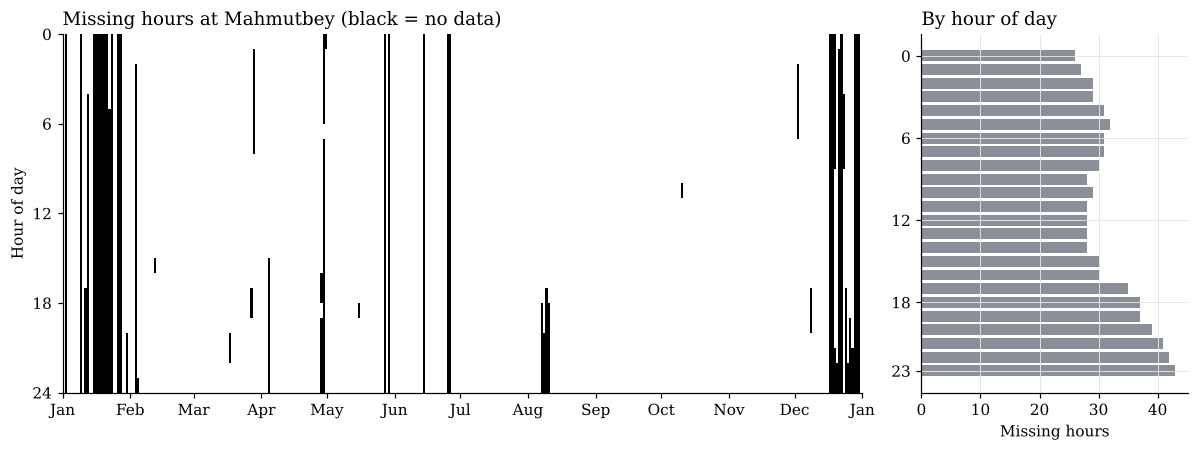

Missing hours        : 769
Fully missing days   : 23 | partially missing days: 30
Missing at 00:00 vs 23:00: 26 vs 43
Coverage across all 251 cells: median 91.2%, min 60.7%


In [2]:
obs=speed.notna().values.reshape(-1, 24)                       # days x hours
days=pd.date_range('2024-01-01', periods=obs.shape[0], freq='D')

fig, (ax1, ax2)=plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={'width_ratios':[3, 1]})
ax1.imshow(~obs.T, aspect='auto', cmap='Greys', interpolation='nearest',
           extent=[mdates.date2num(days[0]), mdates.date2num(days[-1]+pd.Timedelta(days=1)), 24, 0])
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
ax1.set_yticks([0, 6, 12, 18, 24])
ax1.set_ylabel('Hour of day')
ax1.set_title('Missing hours at Mahmutbey (black = no data)', loc='left')
ax1.grid(False)

miss_by_hour=(~obs).sum(axis=0)
ax2.barh(range(24), miss_by_hour, color=GREY, height=0.8)
ax2.invert_yaxis()
ax2.set_yticks([0, 6, 12, 18, 23])
ax2.set_xlabel('Missing hours')
ax2.set_title('By hour of day', loc='left')
fig.tight_layout(); save(fig, 'fig01_missing_hours'); plt.show()

per_day=(~obs).sum(axis=1)
coverage=traffic.groupby('GEOHASH').size()/len(YEAR_INDEX)
print(f'Missing hours        : {(~obs).sum()}')
print(f'Fully missing days   : {(per_day==24).sum()} | partially missing days: {((per_day>0)&(per_day<24)).sum()}')
print(f'Missing at 00:00 vs 23:00: {miss_by_hour[0]} vs {miss_by_hour[23]}')
print(f'Coverage across all 251 cells: median {coverage.median():.1%}, min {coverage.min():.1%}')

> 📝 **TR taslak:** Eksik saatler rastgele değil. 23 gün tamamen boş, 15–21 Ocak arası kesintisiz bir hafta yok.
> Eksikler akşama doğru artıyor, yani kesintiler genelde akşam başlıyor. Neredeyse bütün hücrelerde
> aynı oran (~%91) dolu: sorun tek bir sensör değil, İBB sisteminin tamamı. Bu yüzden komşu hücreler
> Mahmutbey'deki boşlukları dolduramaz.
>
> ➡️ **Model için anlamı:** eksik saatler doldurulsa bile **test metrikleri sadece gerçekten ölçülmüş saatlerde** hesaplanacak. Aksi halde doldurulmuş, tahmini kolay değerler sonucu olduğundan iyi gösterir.

### 1.2 When a daily average lies

> 🔍 **Neden bu tablo?** Eksik veri varken basit özetlerin (günlük ortalama gibi) yanıltıp yanıltmadığını kontrol
> ediyoruz. En yavaş ve en hızlı günlerin kaç saat ölçümle hesaplandığına bakıyoruz.

In [3]:
daily=pd.DataFrame({
    'observed_hours':speed.resample('D').count(),
    'mean_speed':speed.resample('D').mean().round(1),
})
print('Slowest and fastest days by daily mean:')
display(pd.concat([daily.nsmallest(3, 'mean_speed'), daily.nlargest(3, 'mean_speed')]))

print('The hours before the 29 April outage:')
display(target.loc['2024-04-28 12:00':'2024-04-29 23:00'].dropna())

Slowest and fastest days by daily mean:


,observed_hours,mean_speed
DATE_TIME,,
2024-12-19,12,29.0
2024-03-08,24,38.8
2024-12-02,19,39.3
2024-04-29,1,77.0
2024-06-23,24,71.0
2024-06-18,24,70.8


The hours before the 29 April outage:


,MINIMUM_SPEED,MAXIMUM_SPEED,AVERAGE_SPEED,NUMBER_OF_VEHICLES
DATE_TIME,,,,
2024-04-28 12:00:00,16.0,121.0,63.0,52.0
2024-04-28 13:00:00,25.0,95.0,60.0,27.0
2024-04-28 14:00:00,7.0,81.0,46.0,10.0
2024-04-28 15:00:00,11.0,81.0,45.0,7.0
2024-04-28 18:00:00,9.0,79.0,44.0,2.0
2024-04-29 06:00:00,77.0,77.0,77.0,1.0


> 📝 **TR taslak:** "Yılın en yavaş günü" 19 Aralık (29 km/sa) aslında sadece 09–20 arası kaydedilmiş,
> gece saatleri yok. "En hızlı gün" 29 Nisan (77 km/sa) ise tek bir saat: 06:00, **1 araç**.
> Bir önceki gün araç sayısı 10 → 7 → 2'ye düşüyor: sistem kesilmeden önce sönüyor.
> Eksik veri varken günlük ortalamalar yanıltıcı. Az araçlı saatleri de şüpheli kabul edeceğiz.
>
> ➡️ **Model için anlamı:** araç sayısı çok düşük olan saatler güvenilir değil; işlemede "şüpheli" olarak işaretlenecek.

### 1.3 Impossible speeds

> 🔍 **Neden bu grafik?** Veri setinde ortalama hızın yanında minimum ve maksimum hız da var. Bunları modele
> girdi olarak vermeden önce fiziksel olarak mantıklı olup olmadıklarını kontrol ediyoruz.

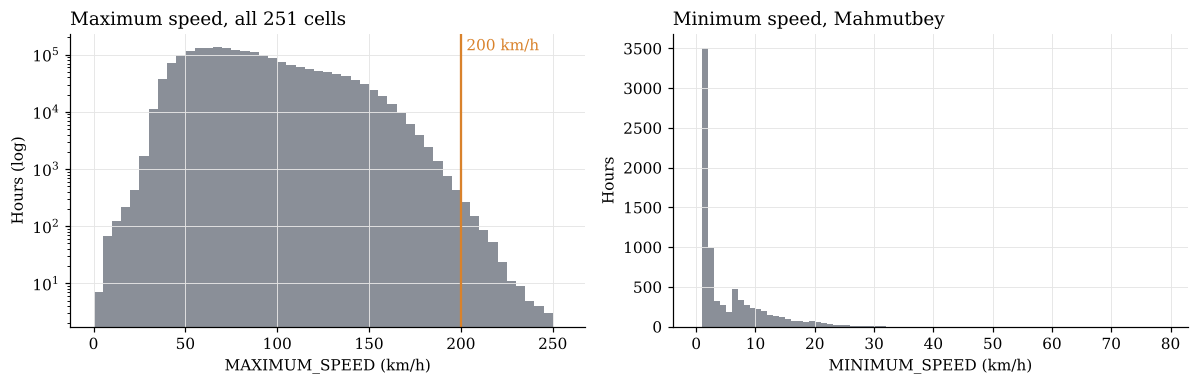

Records with MAX >= 200 km/h (all cells): 618 | highest: 248 km/h
Mahmutbey hours with MIN = 1 km/h: 44%
Rows where AVG is outside [MIN, MAX]: 0


Cells with more than one coordinate: 0


In [4]:
fig, (ax1, ax2)=plt.subplots(1, 2, figsize=(11, 3.6))
ax1.hist(traffic['MAXIMUM_SPEED'], bins=np.arange(0, 260, 5), color=GREY)
ax1.axvline(200, color=ORANGE, lw=1.5)
ax1.text(203, ax1.get_ylim()[1]*0.85, '200 km/h', color=ORANGE)
ax1.set_yscale('log')
ax1.set_xlabel('MAXIMUM_SPEED (km/h)'); ax1.set_ylabel('Hours (log)')
ax1.set_title('Maximum speed, all 251 cells', loc='left')

ax2.hist(target['MINIMUM_SPEED'].dropna(), bins=np.arange(0, 80, 1), color=GREY)
ax2.set_xlabel('MINIMUM_SPEED (km/h)'); ax2.set_ylabel('Hours')
ax2.set_title('Minimum speed, Mahmutbey', loc='left')
fig.tight_layout(); save(fig, 'fig02_min_max_speed'); plt.show()

t=target.dropna()
print(f"Records with MAX >= 200 km/h (all cells): {(traffic['MAXIMUM_SPEED']>=200).sum()} | highest: {traffic['MAXIMUM_SPEED'].max()} km/h")
print(f"Mahmutbey hours with MIN = 1 km/h: {(t['MINIMUM_SPEED']==1).mean():.0%}")
print(f"Rows where AVG is outside [MIN, MAX]: {((traffic['AVERAGE_SPEED']<traffic['MINIMUM_SPEED'])|(traffic['AVERAGE_SPEED']>traffic['MAXIMUM_SPEED'])).sum()}")
print(f"Cells with more than one coordinate: {(traffic.groupby('GEOHASH')[['LATITUDE', 'LONGITUDE']].nunique()>1).any(axis=1).sum()}")

> 📝 **TR taslak:** 618 kayıtta maksimum hız 200 km/sa üstü, en yüksek 248 km/sa. Fiziksel olarak
> imkânsıza yakın, büyük ihtimalle GPS hatası. Minimum hız ise saatlerin %44'ünde 1 km/sa (duran/park
> araçlar). MIN ve MAX tek araçların uç değerleri, gürültülü. **Karar:** modelde sadece AVERAGE_SPEED ve
> araç sayısı kullanılacak. Tutarlılık kontrolleri temiz: ortalama her zaman min–max arasında, her hücrenin
> tek koordinatı var.
>
> Not: Eski `traffic_2024_clean.csv` dosyası bu ham hücreyle birebir aynı çıktı (8.015/8.015 saat),
> yani "clean" adına rağmen temizlenmemişti.

### 1.4 Are traffic and weather on the same clock?

> 🔍 **Neden bu grafik?** Trafik ve hava verisi iki farklı kaynaktan geliyor. Biri UTC, diğeri yerel saatte
> olsaydı, birleştirince yağmurun etkisi 3 saat kaymış görünürdü ve model yanlış ilişki öğrenirdi.
> Basit bir test: hava en sıcak öğleden sonra, trafik en akıcı gece olmalı. İkisini aynı eksende 0–1 aralığına ölçekleyip karşılaştırıyoruz.

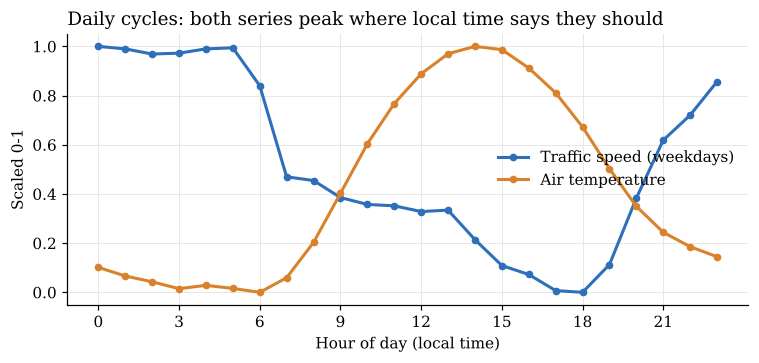

Warmest hour: 14:00 | slowest traffic hour: 18:00


In [5]:
wd=speed[speed.index.dayofweek<5]
hourly_speed=wd.groupby(wd.index.hour).mean()
hourly_temp=weather['temperature'].groupby(weather.index.hour).mean()
norm=lambda s: (s-s.min())/(s.max()-s.min())

fig, ax=plt.subplots(figsize=(7, 3.4))
ax.plot(norm(hourly_speed), color=BLUE, lw=2, marker='o', ms=4, label='Traffic speed (weekdays)')
ax.plot(norm(hourly_temp), color=ORANGE, lw=2, marker='o', ms=4, label='Air temperature')
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel('Hour of day (local time)'); ax.set_ylabel('Scaled 0-1')
ax.set_title('Daily cycles: both series peak where local time says they should', loc='left')
ax.legend(frameon=False)
fig.tight_layout(); save(fig, 'fig03_clock_check'); plt.show()
print(f'Warmest hour: {hourly_temp.idxmax()}:00 | slowest traffic hour: {hourly_speed.idxmin()}:00')

> 📝 **TR taslak:** En sıcak saat 14:00, trafik gece 0–5 arası en akıcı. İki kaynak da Türkiye saatinde,
> birleştirirken kayma yok. (Open-Meteo varsayılan olarak UTC verir; yanlış birleştirmek hava etkisini 3 saat kaydırırdı.)
>
> ➡️ **Model için anlamı:** iki kaynak kaydırma yapmadan doğrudan birleştirilebilir.

### 1.5 Event data vs. missing data

> 🔍 **Neden bu kontrol?** Akaryakıt zam gecelerini olay değişkeni olarak kullanacağız. Bir olayın etkisini
> ölçebilmek için o saatlerde trafik verisi olması gerekiyor; eksik günlere denk gelen olayları sayıyoruz.

In [6]:
fuel_nights=fuel['DATE_TIME'].dt.normalize().drop_duplicates()
lost=[d.date() for d in fuel_nights if speed.loc[d.strftime('%Y-%m-%d')].notna().sum()==0]
print(f'Fuel hike nights: {len(fuel_nights)} | nights with no traffic data at all: {len(lost)} -> {lost}')

Fuel hike nights: 24 | nights with no traffic data at all: 4 -> [datetime.date(2024, 1, 2), datetime.date(2024, 1, 19), datetime.date(2024, 1, 23), datetime.date(2024, 12, 30)]


> 📝 **TR taslak:** 24 zam gecesinin 4'ü tamamen veri olmayan günlere denk geliyor. Bu olayların etkisini
> o günlerde hiç ölçemiyoruz. Akaryakıt değişkeninin katkısını ablation ile test edeceğiz.

## 2 · Study area

> 🔍 **Neden bu harita?** Projeyi tek kavşaktan çevresiyle birlikte modellemeye genişletiyoruz. Bunun için
> (1) Mahmutbey'in hangi hücre olduğunu, (2) çevresindeki hücrelerden hangilerinin onunla birlikte hareket ettiğini
> görmemiz gerekiyor. Her kare bir İBB hücresi; renk, o hücrenin hızının Mahmutbey'in hızıyla korelasyonu.
> Mahmutbey hücresi (`sxk3xe`), eski çalışmadaki veriyle saat saat birebir eşleştirilerek belirlendi.

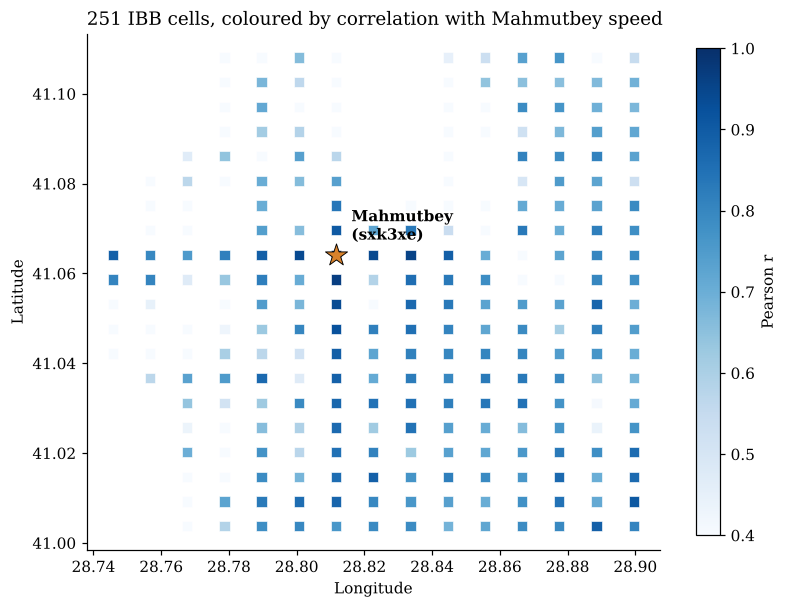

,LATITUDE,LONGITUDE,corr,dist_km
GEOHASH,,,,
sxk3xd,41.059,28.812,0.965,0.611
sxk985,41.064,28.834,0.957,1.844
sxk3xg,41.064,28.823,0.942,0.922
sxk3x7,41.064,28.801,0.940,0.922
sxk3x9,41.053,28.812,0.939,1.223
sxk3x8,41.048,28.812,0.923,1.834
sxk939,41.009,28.900,0.904,9.582
sxk3xs,41.070,28.812,0.902,0.611
sxk3x5,41.064,28.790,0.892,1.844


In [7]:
cells=traffic.groupby('GEOHASH')[['LATITUDE', 'LONGITUDE']].first()
wide=traffic.pivot_table(index='DATE_TIME', columns='GEOHASH', values='AVERAGE_SPEED')
cells['corr']=wide.corrwith(wide[TARGET_CELL])
lat0, lon0=cells.loc[TARGET_CELL, ['LATITUDE', 'LONGITUDE']]
cells['dist_km']=np.hypot((cells['LATITUDE']-lat0)*111.32, (cells['LONGITUDE']-lon0)*111.32*np.cos(np.radians(lat0)))

fig, ax=plt.subplots(figsize=(7.5, 6.3))
sc=ax.scatter(cells['LONGITUDE'], cells['LATITUDE'], c=cells['corr'], cmap='Blues', vmin=0.4, vmax=1,
              s=46, marker='s', edgecolor='white', linewidth=0.4)
ax.scatter(lon0, lat0, s=230, marker='*', color=ORANGE, edgecolor='black', linewidth=0.6, zorder=3)
ax.annotate('Mahmutbey\n(sxk3xe)', (lon0, lat0), xytext=(10, 10), textcoords='offset points', fontweight='bold')
ax.set_aspect(1/np.cos(np.radians(lat0)))
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
ax.set_title('251 IBB cells, coloured by correlation with Mahmutbey speed', loc='left')
ax.grid(False)
fig.colorbar(sc, ax=ax, shrink=0.75, label='Pearson r')
fig.tight_layout(); save(fig, 'fig04_study_area'); plt.show()

display(cells.drop(TARGET_CELL).sort_values('corr', ascending=False).head(10).round(3))

> 📝 **TR taslak:** En ilişkili 6 hücre iki çizgi üzerinde: aynı enlemde doğu–batı (TEM ekseni) ve aynı
> boylamda kuzey–güney (Basın Ekspres bağlantısı). Kavşağın haç şekli, harita bilgisi kullanmadan
> sadece hız korelasyonundan ortaya çıkıyor.
>
> ➡️ **Model için anlamı:** komşuları rastgele değil, Mahmutbey'le ilişkisine ve uzaklığına göre seçeceğiz. Bu harita, makalede çalışma alanını tanıtan figür olacak.

## 3 · What does Mahmutbey traffic look like?

> 🔍 **Neden bu grafik?** Tahmin etmeye çalıştığımız değişkenin (ortalama hız) dağılımını görmek, hangi tür modelin
> uygun olduğunu söyler. Tek tepeli, simetrik bir dağılım basit modellerle iyi tahmin edilir; birden fazla tepe varsa
> model farklı durumları (rejimleri) ayırt edebilmeli.

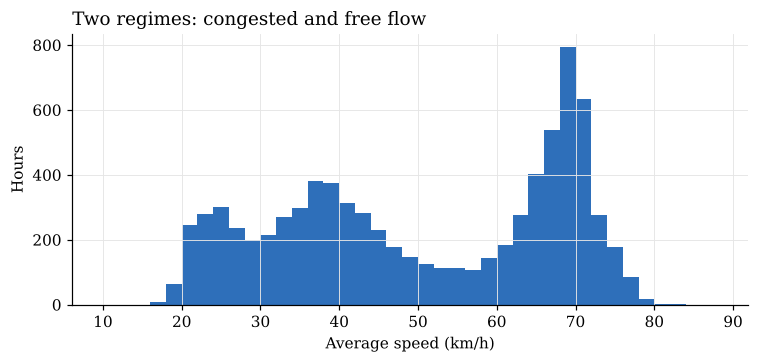

count    8015.0
mean       49.9
std        17.7
min        16.0
25%        35.0
50%        49.0
75%        67.0
max        82.0


In [8]:
fig, ax=plt.subplots(figsize=(7, 3.4))
ax.hist(speed.dropna(), bins=np.arange(10, 90, 2), color=BLUE)
ax.set_xlabel('Average speed (km/h)'); ax.set_ylabel('Hours')
ax.set_title('Two regimes: congested and free flow', loc='left')
fig.tight_layout(); save(fig, 'fig05_speed_distribution'); plt.show()
print(speed.describe().round(1).to_string())

> 🔍 **Neden bu grafik?** Trafiğin günün saatine ve haftanın gününe göre tekrar eden bir düzeni var mı? Varsa model
> bu düzeni takvim değişkenleriyle öğrenebilir. Isı haritası her gün–saat kombinasyonundaki ortalama hızı gösteriyor.

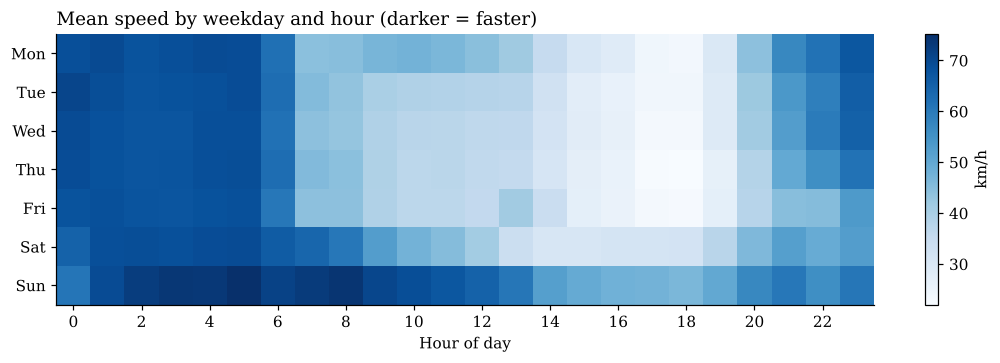

In [9]:
days_order=['Mon', 'Tue', 'Wed', 'Thu', 'Fri', 'Sat', 'Sun']
grid=speed.groupby([speed.index.dayofweek, speed.index.hour]).mean().unstack()

fig, ax=plt.subplots(figsize=(10, 3.4))
im=ax.imshow(grid, aspect='auto', cmap='Blues')
ax.set_yticks(range(7)); ax.set_yticklabels(days_order)
ax.set_xticks(range(0, 24, 2)); ax.set_xlabel('Hour of day')
ax.set_title('Mean speed by weekday and hour (darker = faster)', loc='left')
ax.grid(False)
fig.colorbar(im, ax=ax, label='km/h')
fig.tight_layout(); save(fig, 'fig06_week_heatmap'); plt.show()

> 🔍 **Neden bu grafik?** Otokorelasyon, serinin kendi geçmişiyle ne kadar ilişkili olduğunu gösterir. Modelde
> "1 saat önceki hız", "dün aynı saatteki hız", "geçen hafta aynı saatteki hız" gibi gecikmeli değişkenler kullanacağız;
> hangilerinin bilgi taşıdığını burada görüyoruz.

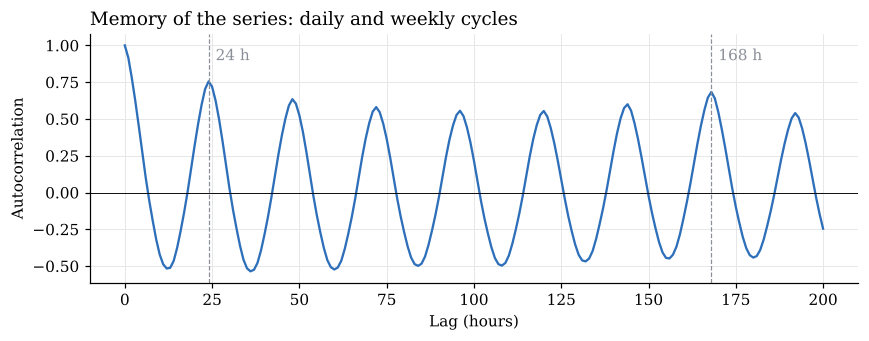

{1: np.float64(0.917), 2: np.float64(0.779), 3: np.float64(0.623), 12: np.float64(-0.517), 24: np.float64(0.755), 48: np.float64(0.634), 168: np.float64(0.684)}


In [10]:
lags=[1, 2, 3, 12, 24, 48, 168]
r=acf(speed.interpolate(limit=3).dropna(), nlags=200, fft=True)

fig, ax=plt.subplots(figsize=(8, 3.2))
ax.plot(range(201), r, color=BLUE, lw=1.5)
for k in [24, 168]:
    ax.axvline(k, color=GREY, lw=0.8, ls='--')
    ax.text(k+2, 0.9, f'{k} h', color=GREY)
ax.axhline(0, color='black', lw=0.6)
ax.set_xlabel('Lag (hours)'); ax.set_ylabel('Autocorrelation')
ax.set_title('Memory of the series: daily and weekly cycles', loc='left')
fig.tight_layout(); save(fig, 'fig07_acf'); plt.show()
print({k:round(r[k], 3) for k in lags})

> 📝 **TR taslak:** Dağılım iki tepeli (sıkışık ~25–35, akıcı ~65–75 km/sa); ortası seyrek, trafik iki rejim
> arasında hızlı geçiyor. Kavşak sabah değil **akşam** kilitleniyor (17–18). Otokorelasyon 24 ve 168 saatte
> tepe yapıyor: günlük ve haftalık döngü. Modeldeki lag seçimleri buna dayanıyor.
>
> ➡️ **Model için anlamı:** model iki rejimi ayırt edebilmeli (bu yüzden "bir önceki hız + değişim" yapısını kullanıyoruz) ve lag seçimleri (1, 24, 168 saat) burada gerekçelendirildi.

## 4 · Speed vs. vehicle count

> 🔍 **Neden bu grafik?** Akla ilk gelen fikir "araç çoksa hız düşüktür". Bu doğruysa araç sayısı tek başına iyi bir
> tahmin değişkeni olurdu. Gri noktalar tek tek saatler, mavi çizgi günün her saatinin ortalaması; çizgiyi saat sırasıyla
> takip edince günün nasıl ilerlediği görülüyor. Bu grafik trafik mühendisliğindeki **temel diyagramın** (hız–akış ilişkisi) bir versiyonu.

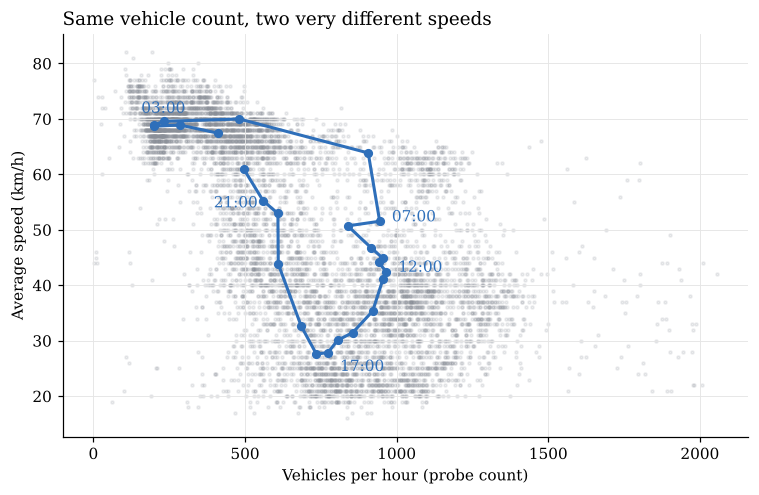

,NUMBER_OF_VEHICLES,AVERAGE_SPEED
DATE_TIME,,
12,965.0,42.0
17,774.0,28.0
18,735.0,28.0


In [11]:
t=target.dropna()
prof=t.groupby(t.index.hour)[['NUMBER_OF_VEHICLES', 'AVERAGE_SPEED']].mean()

fig, ax=plt.subplots(figsize=(7, 4.6))
ax.scatter(t['NUMBER_OF_VEHICLES'], t['AVERAGE_SPEED'], s=4, alpha=0.15, color=GREY, rasterized=True)
ax.plot(prof['NUMBER_OF_VEHICLES'], prof['AVERAGE_SPEED'], color=BLUE, lw=2, marker='o', ms=5)
offsets={3:(-8, 8), 7:(8, 0), 12:(8, 0), 17:(8, -12), 21:(-42, 4)}
for h, off in offsets.items():
    ax.annotate(f'{h:02d}:00', prof.loc[h], xytext=off, textcoords='offset points', color=BLUE)
ax.set_xlabel('Vehicles per hour (probe count)'); ax.set_ylabel('Average speed (km/h)')
ax.set_title('Same vehicle count, two very different speeds', loc='left')
fig.tight_layout(); save(fig, 'fig08_speed_vs_vehicles'); plt.show()
display(prof.loc[[12, 17, 18]].round(0))

> 📝 **TR taslak:** En çok araç öğlen 12'de (~965) geçiyor, en yavaş saatlerde (17–18) araç sayısı daha az
> (~735–775). Tıkanınca birim zamanda geçebilen araç da azalıyor: trafik akış teorisindeki **kapasite
> düşüşü** (capacity drop). Aynı araç sayısında iki farklı hız var, bu yüzden araç sayısı tek başına hızı
> belirlemez; modelin rejimi (akıcı/sıkışık) bilmesi gerekir.
> Not: araç sayısı İBB'nin konum verisindeki örnek araç sayısı, toplam trafik hacmi değil.
>
> ➡️ **Model için anlamı:** araç sayısı yardımcı bir değişken, ama hızı tek başına açıklamaz; modelin trafiğin o an hangi rejimde olduğunu bilmesi gerekir.

## 5 · Calendar and weather effects

> 🔍 **Neden bu grafik?** Eski çalışmada Ramazan ve bayram değişkenleri vardı, ama etkileri veriyle gösterilmemişti.
> Burada Ramazan ayındaki saatlik hız profilini, Ramazan'dan önceki 5 haftayla karşılaştırıyoruz.

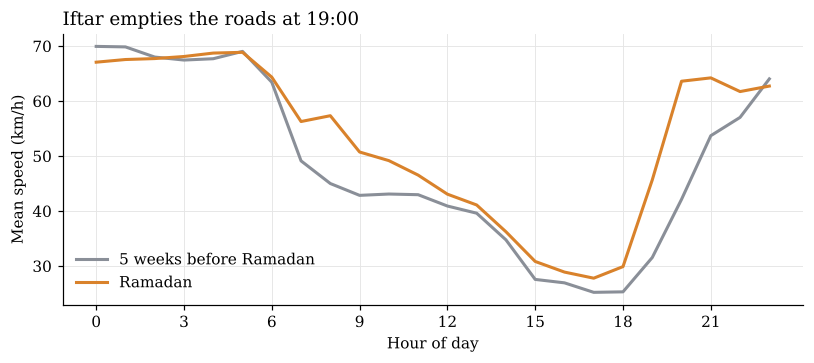

19:00 mean speed -> Ramadan 45.7 | before 31.5 km/h
1-hour jumps >= 25 km/h: 34 | during Ramadan: 12


In [12]:
ramadan=speed.loc['2024-03-11':'2024-04-09']
before=speed.loc['2024-02-05':'2024-03-08']

fig, ax=plt.subplots(figsize=(7.5, 3.4))
ax.plot(before.groupby(before.index.hour).mean(), color=GREY, lw=2, label='5 weeks before Ramadan')
ax.plot(ramadan.groupby(ramadan.index.hour).mean(), color=ORANGE, lw=2, label='Ramadan')
ax.set_xticks(range(0, 24, 3)); ax.set_xlabel('Hour of day'); ax.set_ylabel('Mean speed (km/h)')
ax.set_title('Iftar empties the roads at 19:00', loc='left')
ax.legend(frameon=False)
fig.tight_layout(); save(fig, 'fig09_ramadan'); plt.show()
print(f'19:00 mean speed -> Ramadan {ramadan[ramadan.index.hour==19].mean():.1f} | before {before[before.index.hour==19].mean():.1f} km/h')

jumps=speed.diff().abs()
big=jumps[jumps>=25]
print(f'1-hour jumps >= 25 km/h: {len(big)} | during Ramadan: {big.loc["2024-03-11":"2024-04-09"].count()}')

> 🔍 **Neden bu tablo?** Bayram günlerinin hepsi aynı mı davranıyor? Her bayram gününün ortalama hızını, yılın aynı
> haftagünü ortalamasıyla karşılaştırıyoruz. Ayrıca yağışın ve 8 Mart kar gününün etkisine kısaca bakıyoruz.

In [13]:
dow_mean=speed.groupby(speed.index.dayofweek).mean()
holidays={
    'Ramadan Bayram d1':'2024-04-10', 'Ramadan Bayram d2':'2024-04-11', 'Ramadan Bayram d3':'2024-04-12',
    'Kurban Bayram d1':'2024-06-16', 'Kurban Bayram d2':'2024-06-17', 'Kurban Bayram d3':'2024-06-18', 'Kurban Bayram d4':'2024-06-19',
}
rows=[]
for name, day in holidays.items():
    d=pd.Timestamp(day)
    rows.append({'day':name, 'date':day, 'mean_speed':speed.loc[day].mean(), 'vs_same_weekday':speed.loc[day].mean()-dow_mean[d.dayofweek]})
display(pd.DataFrame(rows).round(1))

wet=speed[weather['rain'].reindex(speed.index)>0.1]
dry=speed[weather['rain'].reindex(speed.index)==0]
print(f'Mean speed in rain {wet.mean():.1f} vs dry {dry.mean():.1f} km/h (not hour-adjusted)')
print(f"8 March (rain {weather.loc['2024-03-08', 'rain'].sum():.0f} mm + snow): daily mean {speed.loc['2024-03-08'].mean():.1f} km/h, rank among slowest: {daily['mean_speed'].rank().loc['2024-03-08']:.0f}")

,day,date,mean_speed,vs_same_weekday
0,Ramadan Bayram d1,2024-04-10,58.9,11.9
1,Ramadan Bayram d2,2024-04-11,58.2,12.2
2,Ramadan Bayram d3,2024-04-12,62.1,16.7
3,Kurban Bayram d1,2024-06-16,63.4,0.7
4,Kurban Bayram d2,2024-06-17,64.7,14.9
5,Kurban Bayram d3,2024-06-18,70.8,23.3
6,Kurban Bayram d4,2024-06-19,70.0,23.0


Mean speed in rain 45.7 vs dry 50.5 km/h (not hour-adjusted)
8 March (rain 16 mm + snow): daily mean 38.8 km/h, rank among slowest: 2


> 📝 **TR taslak:** Ramazan'da saat 19'daki ortalama hız ~46 km/sa, öncesinde ~32 km/sa. 25 km/sa'i aşan ani
> sıçramaların üçte biri Ramazan'da ve iftar saatinde. Bayramlarda Kurban'ın 1. günü neredeyse normal,
> sonraki günler +15–23 km/sa daha hızlı. Eski modelde tek bir "bayram" bayrağı vardı; ilk gün ayrı ele alınmalı.
> 8 Mart'taki yağmur+kar günü yılın en yavaş günlerinden biri.
>
> ➡️ **Model için anlamı:** iftar saati için ayrı bir değişken ve bayramın ilk günü için ayrı bir işaret kullanacağız.

## 6 · Do neighbours see congestion first?

> 🔍 **Neden bu grafik?** Komşu hücreleri modele eklemenin asıl gerekçesi şu olurdu: sıkışma önce komşuda başlayıp
> sonra Mahmutbey'e geliyorsa, komşunun şimdiki durumu Mahmutbey'in bir saat sonrasını haber verir. Bunu test etmek için
> en yakın ve en ilişkili 6 komşunun saatlik hız değişimlerini Mahmutbey'inkilerle farklı zaman kaydırmalarında karşılaştırıyoruz.
> k > 0 tarafında yüksek korelasyon "komşu önce görüyor" demek.

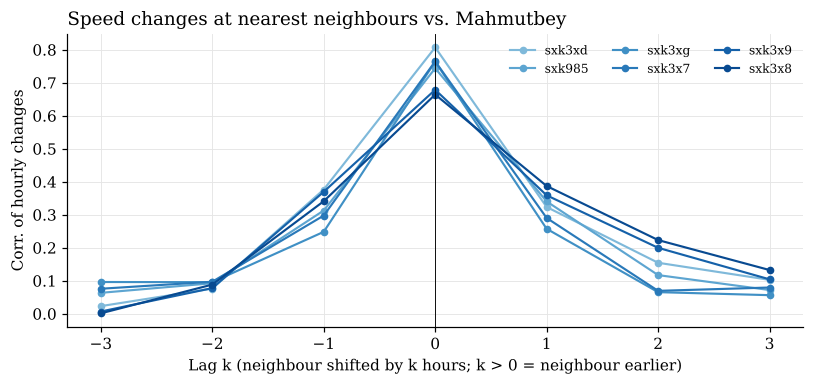

,sxk3xd,sxk985,sxk3xg,sxk3x7,sxk3x9,sxk3x8
-3,0.023,0.063,0.096,0.076,0.007,0.001
-2,0.076,0.092,0.096,0.097,0.078,0.088
-1,0.376,0.313,0.248,0.298,0.370,0.341
0,0.807,0.744,0.764,0.765,0.679,0.664
1,0.323,0.340,0.257,0.290,0.359,0.387
2,0.154,0.117,0.065,0.069,0.200,0.223
3,0.103,0.072,0.056,0.079,0.104,0.132


In [14]:
top=cells.drop(TARGET_CELL).query('dist_km<=3').sort_values('corr', ascending=False).head(6).index
dt=wide[TARGET_CELL].diff()
lag_range=range(-3, 4)
res=pd.DataFrame({c:[dt.corr(wide[c].diff().shift(k)) for k in lag_range] for c in top}, index=list(lag_range))

fig, ax=plt.subplots(figsize=(7.5, 3.6))
for i, c in enumerate(top):
    ax.plot(res.index, res[c], marker='o', ms=4, lw=1.4, color=plt.cm.Blues(0.45+0.09*i), label=c)
ax.axvline(0, color='black', lw=0.6)
ax.set_xlabel('Lag k (neighbour shifted by k hours; k > 0 = neighbour earlier)')
ax.set_ylabel('Corr. of hourly changes')
ax.set_title('Speed changes at nearest neighbours vs. Mahmutbey', loc='left')
ax.legend(frameon=False, ncol=3, fontsize=8)
fig.tight_layout(); save(fig, 'fig10_neighbour_lead'); plt.show()
display(res.round(3))

> 📝 **TR taslak:** Değişimler en çok aynı saatte birlikte oluyor (r ≈ 0.66–0.81). Komşunun 1 saat önceki
> değişimi de Mahmutbey'in şimdiki değişimiyle ilişkili (r ≈ 0.26–0.39), ama ters yön (k = −1) de neredeyse aynı.
> Yani saatlik çözünürlükte belirgin bir "önce komşu sıkışır, sonra Mahmutbey" yönü yok; tıkanıklık bir saatten
> kısa sürede yayılıyor. Komşuların modele katkısı bu yüzden önceden varsayılmayacak, ablation ile ölçülecek.
> (Dürüst bir negatif bulgu; makalede tartışma bölümüne uygun.)
>
> ➡️ **Model için anlamı:** komşu değişkenlerinin katkısını varsaymıyoruz; modellemede komşulu ve komşusuz sürümleri karşılaştırarak ölçeceğiz.

## 7 · Summary and decisions

| Finding | Decision |
|---|---|
| Missing hours are system-wide, not random, more frequent in the evening | Evaluate only on observed hours; report coverage |
| Very low vehicle counts before outages | Flag low-count hours as suspect |
| MIN/MAX speeds contain impossible values | Use AVERAGE_SPEED and vehicle count only |
| Traffic and weather share local time | Join directly, no shift |
| 4 of 24 fuel nights fall in outages | Test fuel feature by ablation |
| Correlated cells form the junction's cross shape | Select neighbours by correlation and distance |
| No clear lead of neighbours at hourly resolution | Measure the value of neighbour features by ablation |
| Two speed regimes, capacity drop | Model must be regime-aware |
| Daily (24 h) and weekly (168 h) memory | Keep lags 1-3, 24, 168 |
| Iftar effect, first Bayram day differs | Separate iftar and Bayram-day-1 features |